### **Summarizing Messages**

#### Set the OpenAI API Key as an Environment Variable

In [1]:
%load_ext dotenv
%dotenv
%load_ext mypy_ipython

#### Import Relevant Classes and Functions

In [2]:
from langgraph.graph import START, END, StateGraph, MessagesState
from langchain_openai.chat_models import ChatOpenAI
from langchain_core.messages import HumanMessage, SystemMessage, AIMessage, RemoveMessage
from typing import Literal

#### Define the State

In [3]:
class State(MessagesState):
    summary: str

In [4]:
test_state = State()

In [5]:
test_state["summary"]

KeyError: 'summary'

In [7]:
bool(test_state.get("summary", ""))

False

#### Define the Nodes

In [8]:
chat = ChatOpenAI(
    model = "gpt-4o",
    seed = 7,
    temperature = 0,
    max_completion_tokens = 100
)

In [9]:
def ask_question(state: State) -> State:

    print(f"\n------> ENTERING ask_question:")

    question = "What is your question?"
    print(question)

    return State(messages = [AIMessage(question), HumanMessage(input())])

In [10]:
def chatbot(state: State) -> State:

    print(f"\n------> ENTERING chatbot:")
    for i in state["messages"]:
        i.pretty_print()

    system_message = f'''
        Here's a quick summary of what's been discussed so far:
        {state.get("summary", "")}

        Keep this in mind as you answer the next question.
    '''
    
    response = chat.invoke([SystemMessage(system_message)] + state["messages"])
    response.pretty_print()

    return State(messages = [response])

In [11]:
def ask_another_question(state: State) -> State:

    print(f"\n------> ENTERING ask_another_question:")

    question = "Would you like to ask one more question (yes/no)"
    print(question)

    return State(messages = [AIMessage(question), HumanMessage(input())])

In [12]:
def summarize_and_delete_messages(state: State) -> State:
    print(f"\n------> ENTERING trim_messages:")

    new_conversation = ""
    for i in state["messages"]:
        new_conversation += f"{i.type}: {i.content}\n\n"

    summary_instructions = f'''
        Update the ongoing summary by incorporating the new lines of conversation below.
        Build upon the previous summary rather than repeating it so that the result reflects the most recent context and developments.

        Previous summary:
        {state.get("summary", "")}

        New Conversation:
        {new_conversation}
    '''

    print(summary_instructions)

    summary = chat.invoke([HumanMessage(summary_instructions)])

    remove_messages = [RemoveMessage(id = i.id) for i in state["messages"][:]]

    return State(messages = remove_messages, summary = summary.content)

#### Define the Routing Function

In [13]:
def routing_function(state: State) -> Literal["summarize_and_delete_messages", "__end__"]:

    if state["messages"][-1].content == "yes":
        return "summarize_and_delete_messages"
    else:
        return "__end__"

#### Define the Graph

In [14]:
graph = StateGraph(State)

In [15]:
graph.add_node("ask_question", ask_question)
graph.add_node("chatbot", chatbot)
graph.add_node("ask_another_question", ask_another_question)
graph.add_node("summarize_and_delete_messages", summarize_and_delete_messages)

graph.add_edge(START, "ask_question")
graph.add_edge("ask_question", "chatbot")
graph.add_edge("chatbot", "ask_another_question")
graph.add_conditional_edges(source = "ask_another_question", path = routing_function)
graph.add_edge("summarize_and_delete_messages", "ask_question")

In [16]:
graph_compiled = graph.compile()

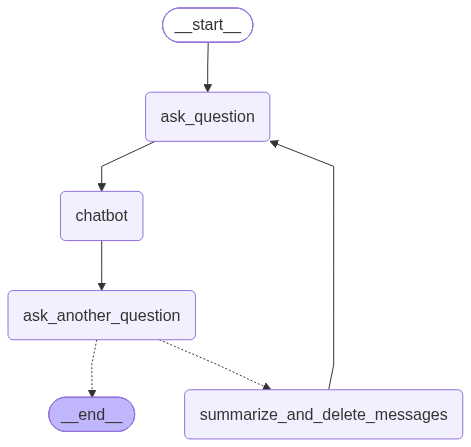

In [17]:
graph_compiled

#### Test the Graph

In [ ]:
graph_compiled.invoke(State(messages = []))


------> ENTERING ask_question:
What is your question?


 Who won the FIFA WC 2002?



------> ENTERING chatbot:
================================== Ai Message ==================================

What is your question?
================================ Human Message =================================

Who won the FIFA WC 2002?
================================== Ai Message ==================================

Brazil won the FIFA World Cup in 2002. They defeated Germany 2-0 in the final match held in Yokohama, Japan.

------> ENTERING ask_another_question:
Would you like to ask one more question (yes/no)


 yes



------> ENTERING trim_messages:

        Update the ongoing summary by incorporating the new lines of conversation below.
        Build upon the previous summary rather than repeating it so that the result reflects the most recent context and developments.

        Previous summary:
        

        New Conversation:
        ai: What is your question?

human: Who won the FIFA WC 2002?

ai: Brazil won the FIFA World Cup in 2002. They defeated Germany 2-0 in the final match held in Yokohama, Japan.

ai: Would you like to ask one more question (yes/no)

human: yes


    

------> ENTERING ask_question:
What is your question?


 What about 1998?


... (17 outputs left out)

 yes



------> ENTERING trim_messages:

        Update the ongoing summary by incorporating the new lines of conversation below.
        Build upon the previous summary rather than repeating it so that the result reflects the most recent context and developments.

        Previous summary:
        The conversation continued with the human asking about the 1986 FIFA World Cup. The AI responded that Argentina won the tournament, defeating West Germany 3-2 in the final at the Estadio Azteca in Mexico City, Mexico. The AI highlighted Diego Maradona's notable performances during the tournament, including the "Hand of God" goal and the "Goal of the Century" against England in the quarter-finals. The AI then asked if the human would like to ask another question, to which

        New Conversation:
        ai: What is your question?

human: What was the first world cup I asked you about?

ai: You first asked about the 1986 FIFA World Cup.

ai: Would you like to ask one more question (yes/no)

human:

 What was my first question?



------> ENTERING chatbot:
================================== Ai Message ==================================

What is your question?
================================ Human Message =================================

What was my first question?
================================== Ai Message ==================================

Your first question was about the 1986 FIFA World Cup.

------> ENTERING ask_another_question:
Would you like to ask one more question (yes/no)
